# PathMNIST: estructura espacial del tejido

Pregunta central: ¿Qué clases de tejido confunde una CNN sencilla y cómo cambian esas confusiones al conservar más detalle espacial?

Este notebook reúne las variantes de resolución, BatchNorm, pooling, acumulación y checkpointing, las extensiones AMP/FP32, aumentos, ResNet-18 y GroupNorm, y la evaluación final ya completada.

Test final: ResNet-18 a 128×128 con aumentos geométricos, elegida por validación, obtuvo 91,53 % de exactitud y 0,8843 de F1 macro sobre 7.180 imágenes. El F1 de validación fue 0,9842. Test se presenta al final y no se usa para ajustar configuraciones.

Selecciona el kernel `.venv`. Por defecto solo se leen archivos guardados: no se entrena, no se descarga el dataset y no se repite inferencia. `results/` contiene la evidencia que viaja a GitHub; los pesos, los datos y MLflow permanecen locales.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for candidate in (Path.cwd(), *Path.cwd().parents):  # Busca la raíz desde la carpeta actual para funcionar tanto al abrir desde el proyecto como desde notebooks
    if (candidate / 'pyproject.toml').exists():
        ROOT = candidate
        break
else:
    raise RuntimeError('No se encontró la raíz del proyecto')
RUNS = ROOT / 'runs'
EVIDENCE = ROOT / 'results'
DATA = ROOT / 'data'
CLASS_NAMES = ['adipose', 'background', 'debris', 'lymphocytes', 'mucus',
               'smooth_muscle', 'normal_colon', 'stroma', 'tumor_epithelium']
SELECTION = json.loads((EVIDENCE / 'final_selection.json').read_text())  # Recupera la elección fijada antes de consultar test, sin volver a seleccionar el modelo

# Prefiere la evidencia publicada y permite revisar corridas locales nuevas
run_paths = {folder.name: folder for folder in (EVIDENCE / 'runs').glob('*')
             if (folder / 'config.json').exists()}
for folder in RUNS.glob('*'):
    if (folder / 'config.json').exists():
        run_paths.setdefault(folder.name, folder)  # Añade corridas locales nuevas sin sustituir las copias de evidencia ya publicadas

print('Raíz del proyecto localizada')
print('Corridas disponibles:', len(run_paths))
print('Selección final fijada:', SELECTION['run'])


Raíz del proyecto localizada
Corridas disponibles: 29
Selección final fijada: 20261016_064401_184180_resnet18_geometric


## 1. Exploración inicial

PathMNIST contiene parches RGB de histología de colon y nueve clases de tejido. Las particiones oficiales tienen 89.996 imágenes de entrenamiento, 10.004 de validación y 7.180 de test.

Las muestras siguientes son las imágenes conservadas de validación a 28×28. Permiten observar textura, color y organización del tejido; una imagen por clase no representa toda su variabilidad. El bloque opcional permite revisar el balance de entrenamiento y la variación dentro de cada clase con los datos locales.


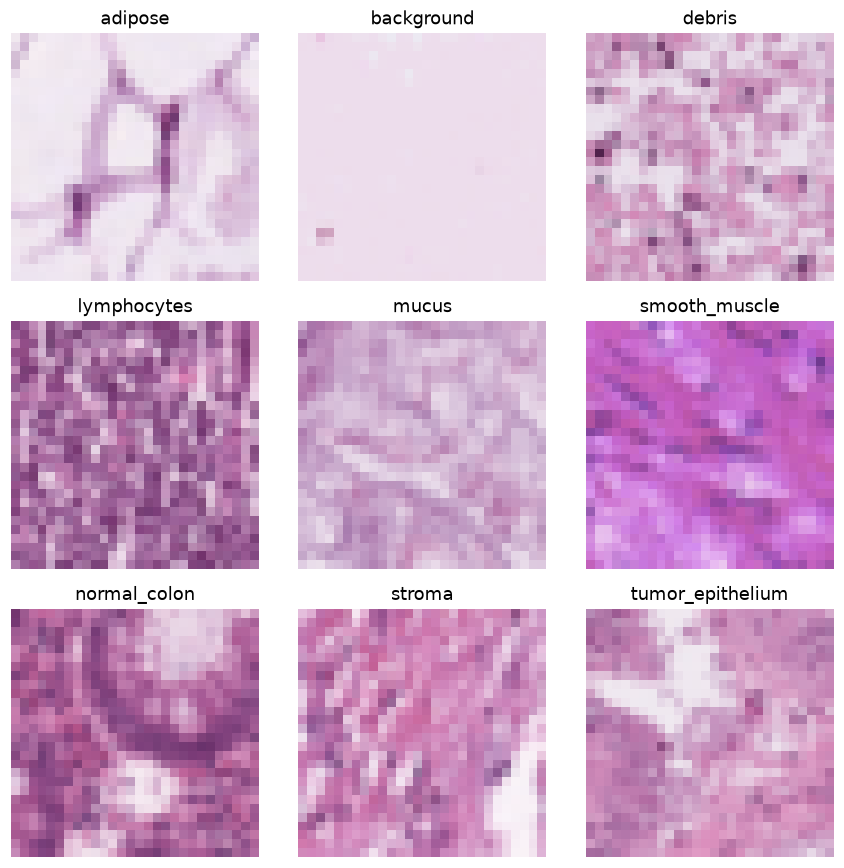

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for class_id, ax in enumerate(axes.flat):
    ax.imshow(plt.imread(EVIDENCE / 'examples' / f'class_{class_id}.png'))  # Muestra la muestra conservada de cada clase sin cargar el dataset completo
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis('off')
plt.tight_layout()
plt.show()

LOAD_LOCAL_EDA = False  # Activa solo si quieres abrir el dataset local, sin descargarlo
if LOAD_LOCAL_EDA:
    from medmnist import PathMNIST
    dataset = PathMNIST(split='train', size=28, root=str(DATA), download=False)
    labels = np.asarray(dataset.labels).reshape(-1)  # Convierte las etiquetas de forma [N, 1] en un vector para contar y filtrar por clase
    counts = pd.Series(labels).value_counts().reindex(range(9), fill_value=0)  # Mantiene el orden oficial de las clases y asigna cero si alguna no aparece
    display(pd.DataFrame({'clase': CLASS_NAMES, 'n_train': counts.to_numpy()}))
    fig, axes = plt.subplots(9, 4, figsize=(9, 18))
    for class_id, row_axes in enumerate(axes):
        for ax, index in zip(row_axes, np.flatnonzero(labels == class_id)[:4]):  # Escoge cuatro imágenes por clase para explorar variación, no una muestra aleatoria representativa
            image, _ = dataset[int(index)]
            ax.imshow(image)
            ax.set_title(CLASS_NAMES[class_id], fontsize=8)
            ax.axis('off')
    plt.tight_layout()
    plt.show()


## 2. Hipótesis antes de las nuevas corridas

La primera corrida, `baseline_28` (28 × 28, con BatchNorm), ya se entrenó. Esta hipótesis se formula después de observar esa corrida y antes de entrenar las nuevas variantes; no es una predicción previa al baseline.

Observación en validación: de 1432 imágenes reales de `tumor_epithelium`, 348 se predijeron como `debris` (24,3 %). El recall de `tumor_epithelium` fue 0,565; el macro F1 general, 0,769. Esta es la confusión dirigida más frecuente de la corrida.

Hipótesis principal (resolución): al entrenar la misma `SimpleCNN` con BatchNorm a 64 × 64, la proporción de imágenes de `tumor_epithelium` clasificadas como `debris` será menor que a 28 × 28 y aumentará el recall de `tumor_epithelium`. A 128 × 128 esperamos la misma dirección frente a 28 × 28, sin suponer que 128 supere necesariamente a 64. La motivación es que una mayor resolución conserva más detalle espacial para distinguir ambas clases.

Medida principal: `tumor→debris = matriz[tumor_epithelium, debris] / total real de tumor_epithelium`. En el baseline vale `348 / 1432 = 0,243`. Compararemos esta tasa y el recall a resolución fija de BatchNorm (`True`), con las mismas épocas, lote, semilla y demás hiperparámetros. Una caída de accuracy global por sí sola no decide esta hipótesis: importa la confusión específica. Si la tasa no baja o el recall no sube, la hipótesis no queda apoyada por esa corrida.

Pregunta secundaria (BatchNorm): a cada resolución, ¿cambian esa confusión, el macro F1 y las curvas de entrenamiento al quitar BatchNorm? Esta comparación es exploratoria; no anticipamos una dirección. Con una sola semilla, los resultados serán descriptivos y necesitarían repeticiones para afirmar que las diferencias son estables. Pregunta secundaria (promedio global): a resolución y BatchNorm fijos, ¿cambian la confusión `tumor→debris`, el macro F1 y el tiempo al conservar todas las posiciones de los mapas? La capa final también tendrá más parámetros, así que interpretaremos la diferencia como efecto conjunto de conservar posición y ampliar el clasificador. En esa etapa, test permanecía reservado hasta elegir la configuración final; la evaluación posterior se documenta en la sección 10.


## 3. Entrenamiento opcional

Se conserva la celda de las doce variantes SimpleCNN, desactivada por defecto. Las corridas completas compatibles se reutilizan. BatchNorm sigue viendo el lote físico aunque se acumulen gradientes.

Para reproducir los otros estudios existen `scripts/run_experiments.py` (variantes base y memoria), `scripts/run_amp_comparison.py` (tres semillas AMP/FP32) y `scripts/run_augmentation_resnet.py` (aumentos, transferencia y GroupNorm). La cola de aumentos contiene esperas específicas de GPU y del servicio local del experimento original; revisarla antes de ejecutarla en otro equipo.

MLflow solo es necesario al entrenar con registro activado. Inícialo con `uv run mlflow server --host 127.0.0.1 --port 5000`, o usa `MLFLOW_URI = None` para guardar solo archivos locales. Ejecutar todo este notebook con las opciones por defecto no inicia MLflow ni modifica sus corridas.


In [3]:
# Cambia a True únicamente cuando quieras iniciar los entrenamientos
RUN_TRAINING = False
RESOLUTIONS_TO_TRAIN = (28, 64, 128)
BATCH_NORM_OPTIONS = (True, False)
ADAPTIVE_POOL_OPTIONS = (True, False)
EPOCHS = 10
BATCH_SIZE = 128  # Lote físico: imágenes que entran juntas en la GPU
ACCUMULATION_STEPS = 1  # Con 4 y BATCH_SIZE=32, lote efectivo nominal de 128
GRADIENT_CHECKPOINTING = False  # Recalcula activaciones en backward para ahorrar memoria
SEED = 42
SKIP_COMPLETED = True
MLFLOW_URI = "http://127.0.0.1:5000"

if RUN_TRAINING:
    import json
    import subprocess
    import sys
    from itertools import product
    from pathlib import Path

    project_root = Path.cwd()
    for folder in (project_root, *project_root.parents):
        if (folder / "pyproject.toml").exists():
            project_root = folder
            break
    else:
        raise RuntimeError("No se encontró la carpeta del proyecto.")

    for size, batch_norm, adaptive_pool in product(  # Genera las combinaciones de resolución, BatchNorm y pooling indicadas arriba
        RESOLUTIONS_TO_TRAIN, BATCH_NORM_OPTIONS, ADAPTIVE_POOL_OPTIONS
    ):
        if size not in (28, 64, 128, 224):
            raise ValueError(f"Resolución no disponible en PathMNIST: {size}")
        if not isinstance(batch_norm, bool) or not isinstance(adaptive_pool, bool):
            raise TypeError("Las opciones de BatchNorm y pooling deben ser booleanas.")

        variant = f"{size}×{size}, BN={batch_norm}, promedio global={adaptive_pool}, acumulación={ACCUMULATION_STEPS}, checkpoint={GRADIENT_CHECKPOINTING}"
        architecture = "SimpleCNN-3blocks-GAP" if adaptive_pool else "SimpleCNN-3blocks-Flatten"
        completed = []
        if SKIP_COMPLETED:
            for run in (project_root / "runs").glob("*"):
                config_file = run / "config.json"
                if not all((config_file.exists(), (run / "best_model.pt").exists(),
                            (run / "duration.json").exists(),
                            (run / "validation_metrics.json").exists())):
                    continue
                config = json.loads(config_file.read_text())
                if (config.get("study", "main") == "main"  # Excluye extensiones y exige la misma configuración antes de reutilizar una corrida
                        and config.get("model", "simplecnn") == "simplecnn"
                        and config.get("augmentation", "none") == "none"
                        and config.get("normalization", "batch" if config.get("batch_norm", True) else "none") == ("batch" if batch_norm else "none")
                        and config.get("learning_rate") == 1e-3
                        and config.get("weight_decay") == 1e-4
                        and config.get("amp", True) is True
                        and config.get("size") == size and config.get("epochs") == EPOCHS
                        and config.get("batch_size") == BATCH_SIZE
                        and config.get("accumulation_steps", 1) == ACCUMULATION_STEPS
                        and config.get("gradient_checkpointing", False) is GRADIENT_CHECKPOINTING
                        and config.get("seed") == SEED
                        and config.get("batch_norm", True) is batch_norm
                        and config.get("adaptive_pool", True) is adaptive_pool
                        and config.get("architecture") == architecture):
                    completed.append(run)

        if completed:
            existing = sorted(completed)[-1]  # Usa la corrida compatible más reciente según su nombre con fecha
            existing_config = json.loads((existing / "config.json").read_text())
            if MLFLOW_URI is not None and not existing_config.get("mlflow_run_id"):  # Importa una corrida local sin reentrenarla si todavía no tiene registro en MLflow
                subprocess.run(
                    [sys.executable, "-m", "pathmnist_tissue.cli", "sync-mlflow",
                     str(existing), "--mlflow-uri", MLFLOW_URI],
                    cwd=project_root, check=True,
                )
            print(f"{variant}: corrida completa encontrada; se omite.")
            continue

        print(f"Entrenando {variant}...", flush=True)
        command = [
            sys.executable, "-m", "pathmnist_tissue.cli", "train",  # Usa el Python del kernel para mantener las mismas dependencias al lanzar el entrenamiento
            "--name", f"simplecnn_{size}_bn_{int(batch_norm)}_gap_{int(adaptive_pool)}_acc{ACCUMULATION_STEPS}_cp{int(GRADIENT_CHECKPOINTING)}",
            "--size", str(size), "--epochs", str(EPOCHS),
            "--batch-size", str(BATCH_SIZE), "--seed", str(SEED),
            "--accumulation-steps", str(ACCUMULATION_STEPS),
            "--gradient-checkpointing" if GRADIENT_CHECKPOINTING else "--no-gradient-checkpointing",
            "--batch-norm" if batch_norm else "--no-batch-norm",
            "--adaptive-pool" if adaptive_pool else "--no-adaptive-pool",
        ]
        if MLFLOW_URI is not None:
            command += ["--mlflow-uri", MLFLOW_URI]
        subprocess.run(command, cwd=project_root, check=True)  # Ejecuta desde la raíz y detiene la celda si el proceso de entrenamiento falla
else:
    print("Entrenamiento desactivado. Cambia RUN_TRAINING a True para iniciarlo.")


Entrenamiento desactivado. Cambia RUN_TRAINING a True para iniciarlo.


## 4. Corridas guardadas y ranking de validación

La tabla distingue arquitectura, normalización, aumentos, precisión, lote físico y acumulación. Solo se consideran completas las corridas con duración, métricas y matriz de validación guardadas. Las métricas globales provienen del reporte por clase, que puede diferir de la métrica del bucle de selección en corridas antiguas con AMP.

El ranking mezcla intervenciones y semillas, por lo que no identifica por sí mismo la causa de una mejora. Su orden utiliza únicamente F1 macro de validación, con empate por orden de ruta, como el registro de selección final. Test no participa.


In [4]:
rows = []
for name, folder in sorted(run_paths.items()):
    if not all((folder / file).exists() for file in (  # Evita incluir corridas incompletas en las métricas y comparaciones
        'duration.json', 'validation_metrics.json', 'validation_confusion_matrix.csv', 'best_validation.json'
    )):
        continue
    config = json.loads((folder / 'config.json').read_text())
    best = json.loads((folder / 'best_validation.json').read_text())
    resources = json.loads((folder / 'duration.json').read_text())
    report = json.loads((folder / 'validation_metrics.json').read_text())
    matrix = pd.read_csv(folder / 'validation_confusion_matrix.csv', index_col=0)
    model_name = config.get('model', 'simplecnn')  # Interpreta las corridas antiguas sin este campo como SimpleCNN
    normalization = config.get('normalization', 'batch' if config.get('batch_norm', True) else 'none')
    gap = config.get('adaptive_pool', True)
    fc_parameters = (512 * 9 + 9 if model_name == 'resnet18'  # Cuenta pesos y sesgos del clasificador final, no todos los parámetros del modelo
                     else 9 * 128 * (1 if gap else (config['size'] // 8) ** 2) + 9)
    rows.append(dict(
        corrida=name, nombre=config['name'], modelo=model_name,
        estudio=config.get('study', 'main'), resolucion=config['size'],
        normalizacion=normalization, aumentos=config.get('augmentation', 'none'),
        precision=config.get('precision', 'AMP según motor original'), semilla=config['seed'],
        epocas=config['epochs'], learning_rate=config['learning_rate'], weight_decay=config['weight_decay'],
        batch_size=config['batch_size'], accumulation_steps=config.get('accumulation_steps', 1),
        effective_batch_size=config['batch_size'] * config.get('accumulation_steps', 1),
        gradient_checkpointing=config.get('gradient_checkpointing', False),
        batch_norm=config.get('batch_norm', True), adaptive_pool=gap, fc_parameters=fc_parameters,
        mejor_epoca=best['epoch'], val_loss=best['loss'], val_accuracy=report['accuracy'],
        val_macro_f1=report['macro avg']['f1-score'], tumor_recall=report['tumor_epithelium']['recall'],  # Usa el reporte por clase guardado, que puede diferir del bucle de validación antiguo con AMP
        tumor_to_debris_rate=matrix.loc['tumor_epithelium', 'debris'] / matrix.loc['tumor_epithelium'].sum(),  # Divide por el total real de tumor para medir su confusión dirigida hacia residuos
        minutos=resources['train_seconds'] / 60, peak_gpu_memory_mb=resources.get('peak_gpu_memory_mb'),
    ))
summary = pd.DataFrame(rows)
if summary.empty:
    raise RuntimeError('No se encontraron resultados completos en results/runs ni runs')
ranking = summary.sort_values(['val_macro_f1', 'corrida'], ascending=[False, True])  # Ordena por validación y resuelve empates por ruta, sin utilizar resultados de test
display(ranking[['nombre', 'modelo', 'normalizacion', 'aumentos', 'precision', 'semilla',
                 'resolucion', 'val_accuracy', 'val_macro_f1', 'tumor_recall', 'minutos']])
print(f'{len(summary)} corridas completas con evaluación, de {len(run_paths)} carpetas')


27 corridas completas con evaluación, de 29 carpetas


,nombre,modelo,normalizacion,aumentos,precision,semilla,resolucion,val_accuracy,val_macro_f1,tumor_recall,minutos
23,resnet18_geometric,resnet18,batch,geometric,amp_fp16,42,128,0.983906,0.984174,0.975559,11.264115
22,resnet18_pretrained,resnet18,batch,none,amp_fp16,42,128,0.975510,0.975785,0.972765,7.570367
17,amp_comparison_seed42_fp32,simplecnn,batch,none,fp32,42,128,0.971411,0.970548,0.978352,12.143414
14,simplecnn_128_bn1_gap1_b32_acc4_cp0,simplecnn,batch,none,AMP según motor original,42,128,0.967413,0.966413,0.977654,8.079097
15,simplecnn_128_bn1_gap1_b32_acc4_cp1,simplecnn,batch,none,AMP según motor original,42,128,0.967413,0.966413,0.977654,12.732269
16,amp_comparison_seed42_amp,simplecnn,batch,none,amp_fp16,42,128,0.967413,0.966413,0.977654,8.084385
24,simplecnn_geometric,simplecnn,batch,geometric,amp_fp16,42,128,0.966313,0.965369,0.930168,9.228254
26,simplecnn_128_groupnorm,simplecnn,group,none,amp_fp16,42,128,0.958617,0.957001,0.949721,13.052905
11,simplecnn_128_bn0_gap0_b128_acc1_cp0,simplecnn,none,none,AMP según motor original,42,128,0.950320,0.949046,0.960196,7.040657
20,amp_comparison_seed44_amp,simplecnn,batch,none,amp_fp16,44,128,0.947621,0.946931,0.983240,32.783632


## 5. Comparaciones controladas de SimpleCNN

Se separan las doce variantes de resolución, BatchNorm y pooling de las extensiones. Se fijan diez épocas, semilla 42, learning rate 0,001, weight decay 0,0001, sin aumentos, sin GroupNorm ni estudio AMP/FP32. Los controles principales usan lote 128×1 y sin checkpointing.

Las curvas de comparación muestran F1 macro, confusión tumor → residuos, recall de tumor y tiempo. Las diferencias son descriptivas para una semilla, no pruebas de significancia estadística.


,resolucion,normalizacion,adaptive_pool,fc_parameters,val_macro_f1,tumor_recall,tumor_to_debris_rate,minutos
4,28,batch,False,10377,0.777831,0.676676,0.098464,0.610440
6,64,batch,False,73737,0.859352,0.900140,0.061453,2.391406
9,128,batch,False,294921,0.870334,0.787709,0.000000,8.884319
0,28,batch,True,1161,0.768524,0.564944,0.243017,0.606258
2,64,batch,True,1161,0.856566,0.981145,0.000000,2.220271
8,128,batch,True,1161,0.766908,0.705307,0.109637,10.492412
5,28,none,False,10377,0.868557,0.901536,0.030726,0.620883
7,64,none,False,73737,0.944651,0.920391,0.008380,2.182978
11,128,none,False,294921,0.949046,0.960196,0.000000,7.040657
1,28,none,True,1161,0.825584,0.798184,0.074022,0.604066


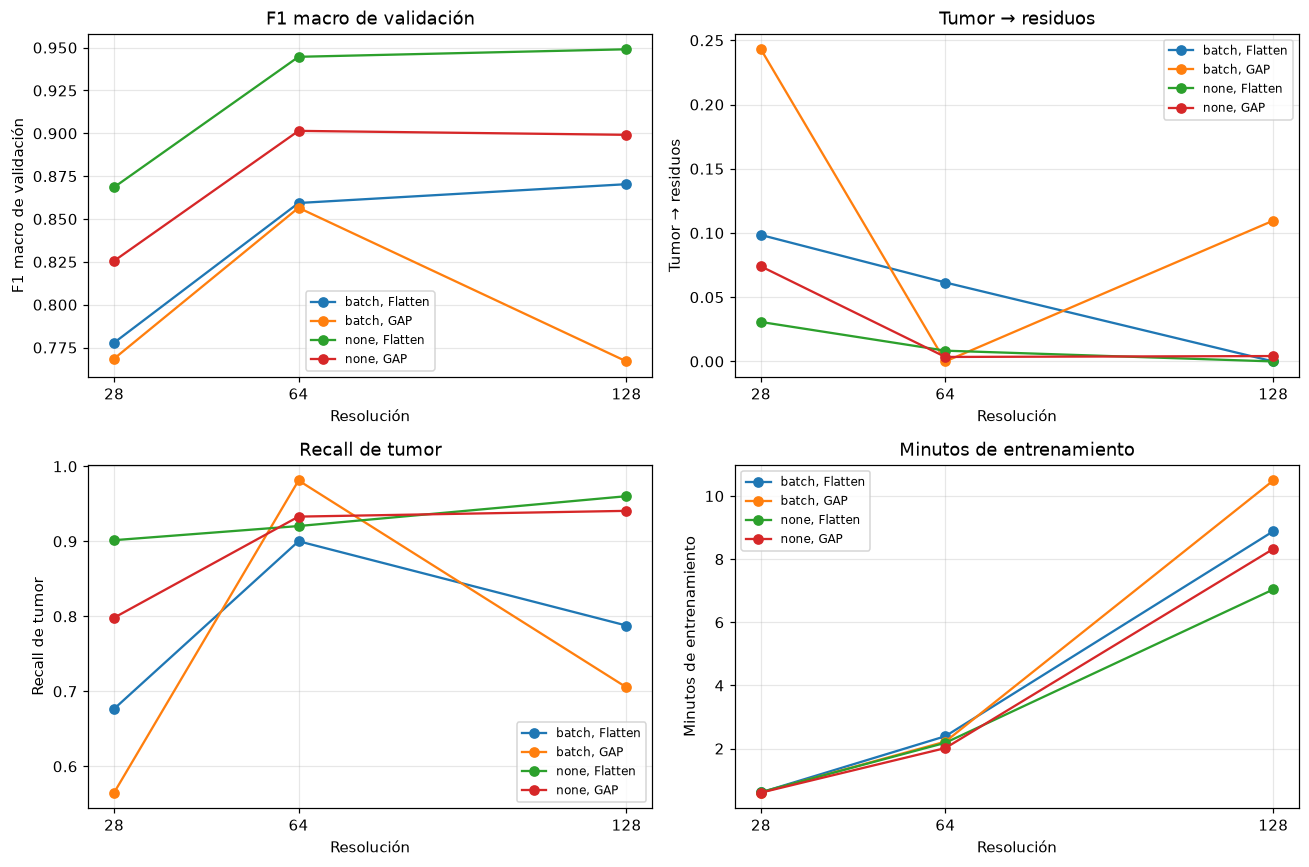

,normalizacion,batch_size,accumulation_steps,gradient_checkpointing,peak_gpu_memory_mb,minutos,val_macro_f1
8,batch,128,1,False,813.539062,10.492412,0.766908
10,none,128,1,False,589.522949,8.323896,0.899125
12,none,32,4,False,161.752441,6.690424,0.908735
13,none,32,4,True,130.701660,8.728471,0.908735
14,batch,32,4,False,217.646484,8.079097,0.966413
15,batch,32,4,True,162.718750,12.732269,0.966413


In [5]:
main = summary.loc[  # Separa los controles SimpleCNN de aumentos, GroupNorm y el estudio AMP/FP32
    (summary['modelo'] == 'simplecnn') & (summary['estudio'] == 'main')
    & (summary['normalizacion'].isin(['batch', 'none'])) & (summary['aumentos'] == 'none')
    & (summary['semilla'] == 42) & (summary['epocas'] == 10)
    & (summary['learning_rate'] == 1e-3) & (summary['weight_decay'] == 1e-4)
].copy()
base = main.loc[(main['batch_size'] == 128) & (main['accumulation_steps'] == 1)  # Fija el lote físico y la ausencia de acumulación para comparar resolución, normalización y pooling
                & ~main['gradient_checkpointing']]
comparison = (base.sort_values('corrida')
              .drop_duplicates(['resolucion', 'normalizacion', 'adaptive_pool'], keep='last')  # Conserva la corrida más reciente de cada combinación tras ordenar por fecha en el nombre
              .sort_values(['normalizacion', 'adaptive_pool', 'resolucion']))
display(comparison[['resolucion', 'normalizacion', 'adaptive_pool', 'fc_parameters',
                    'val_macro_f1', 'tumor_recall', 'tumor_to_debris_rate', 'minutos']])
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for (normalization, gap), group in comparison.groupby(['normalizacion', 'adaptive_pool']):  # Cada línea cambia solo la resolución dentro de la misma normalización y clasificador
    label = f'{normalization}, {"GAP" if gap else "Flatten"}'
    for ax, field, title in zip(axes.flat,
            ['val_macro_f1', 'tumor_to_debris_rate', 'tumor_recall', 'minutos'],
            ['F1 macro de validación', 'Tumor → residuos', 'Recall de tumor', 'Minutos de entrenamiento']):
        ax.plot(group['resolucion'], group[field], marker='o', label=label)
        ax.set(xlabel='Resolución', ylabel=title, title=title)
        ax.set_xticks([28, 64, 128])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

memory = (main.loc[(main['resolucion'] == 128) & main['adaptive_pool']]  # Fija resolución y GAP para revisar lote físico, acumulación y checkpointing por separado
          .sort_values('corrida')
          .drop_duplicates(['normalizacion', 'batch_size', 'accumulation_steps', 'gradient_checkpointing'], keep='last'))
display(memory[['normalizacion', 'batch_size', 'accumulation_steps', 'gradient_checkpointing',
                'peak_gpu_memory_mb', 'minutos', 'val_macro_f1']])


## 6. Curvas de entrenamiento y validación

Se muestran las doce variantes base en paneles separados por normalización y clasificador para evitar superponer estudios distintos. Líneas continuas: validación; discontinuas: entrenamiento. Las curvas se leen de `history.csv`; en las corridas antiguas pueden usar AMP, mientras que el reporte por clase guardado se obtuvo en FP32.


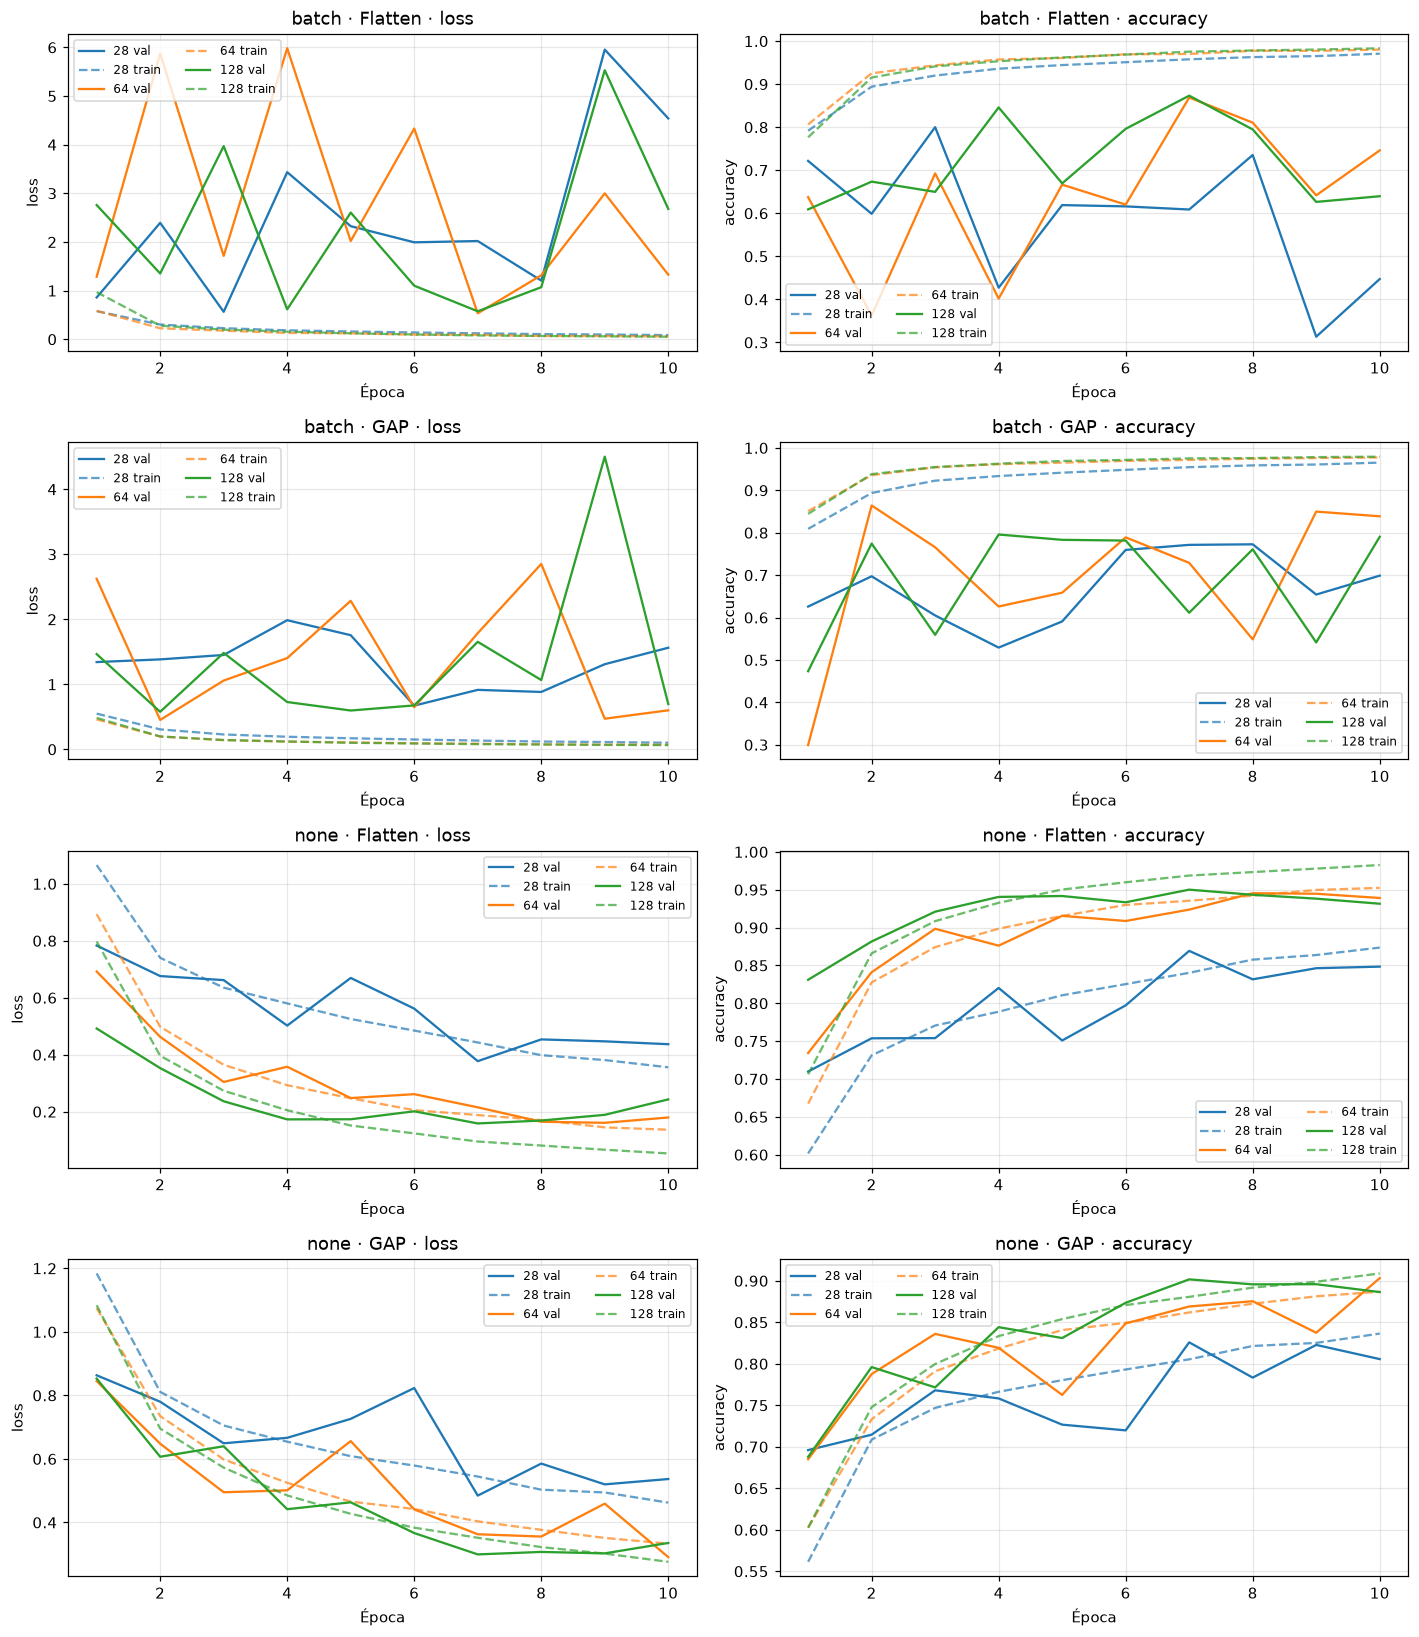

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for row_index, ((normalization, gap), group) in enumerate(comparison.groupby(['normalizacion', 'adaptive_pool'])):  # Separa los cuatro controles de normalización y clasificador en filas para no mezclar estudios
    for _, row in group.iterrows():
        history = pd.read_csv(run_paths[row['corrida']] / 'history.csv')  # Lee la trayectoria original de entrenamiento, sin recalcular métricas ni cargar pesos
        for ax, metric in zip(axes[row_index], ['loss', 'accuracy']):
            line, = ax.plot(history['epoch'], history[f'val_{metric}'], label=f"{row['resolucion']} val")
            ax.plot(history['epoch'], history[f'train_{metric}'], '--', color=line.get_color(),
                    alpha=0.7, label=f"{row['resolucion']} train")  # Mantiene el color de validación y usa trazo discontinuo para su entrenamiento correspondiente
            ax.set(xlabel='Época', ylabel=metric,
                   title=f'{normalization} · {"GAP" if gap else "Flatten"} · {metric}')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


## 7. Errores por clase en validación

Por defecto se analiza la validación de la corrida final fijada en `final_selection.json`. La celda lee métricas y predicciones guardadas, sin ejecutar inferencia. Para revisar otra corrida, cambia `RUN_TO_ANALYZE` por su nombre exacto.

La matriz se normaliza por clase real. Se enumeran los pares de error más frecuentes y sus índices de imagen; cargar las imágenes originales es opcional y requiere el dataset local.


,precision,recall,f1-score,support
adipose,1.000000,0.998079,0.999038,1041.0
background,1.000000,0.998108,0.999053,1057.0
debris,0.985281,0.987847,0.986563,1152.0
lymphocytes,0.998267,0.996540,0.997403,1156.0
mucus,0.975528,0.985393,0.980436,890.0
smooth_muscle,0.985660,0.964549,0.974991,1354.0
normal_colon,0.987400,0.982896,0.985143,877.0
stroma,0.937327,0.973206,0.954930,1045.0
tumor_epithelium,0.984496,0.975559,0.980007,1432.0


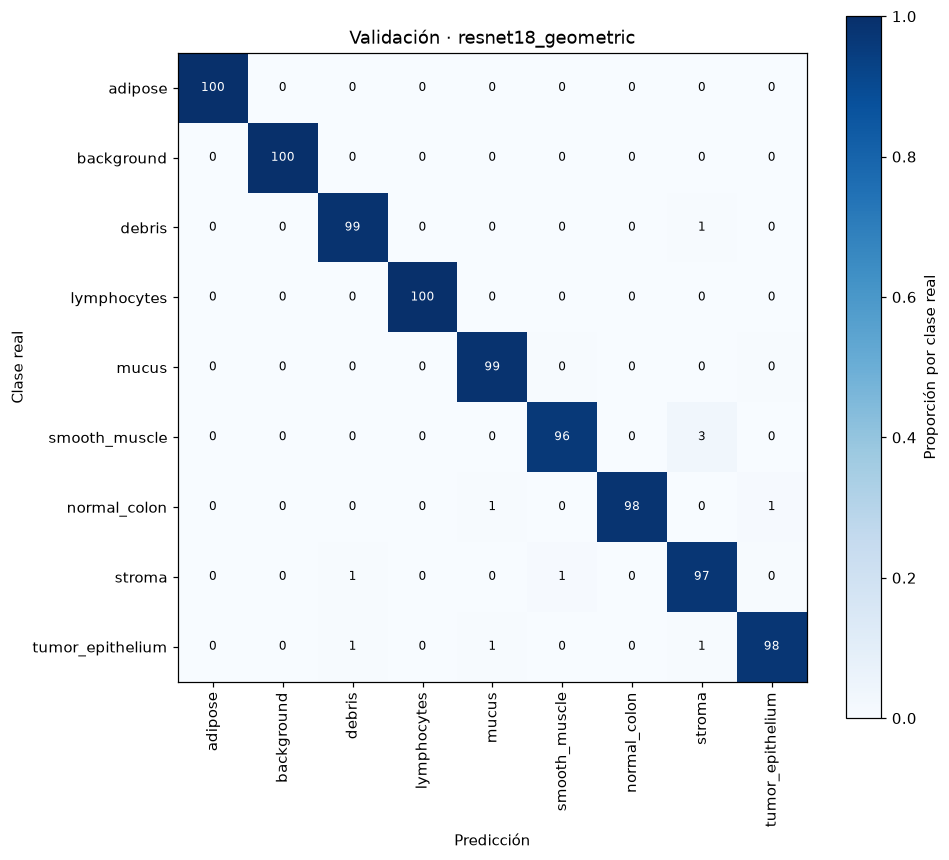

,clase_real,prediccion,casos
46,smooth_muscle,stroma,44
61,stroma,smooth_muscle,10
71,tumor_epithelium,stroma,10
66,tumor_epithelium,debris,9
68,tumor_epithelium,mucus,9
22,debris,stroma,8


,sample_index,true_class,predicted_class
222,222,5,7
308,308,5,7
675,675,5,7
694,694,5,7
845,845,5,7
2068,2068,5,7


In [7]:
RUN_TO_ANALYZE = SELECTION['run']  # Analiza la validación del modelo final por defecto, no elige una corrida por sus errores de test
SHOW_ERROR_IMAGES = False  # Requiere las imágenes locales y no descarga datos
selected_run = run_paths[RUN_TO_ANALYZE]
config = json.loads((selected_run / 'config.json').read_text())
report = json.loads((selected_run / 'validation_metrics.json').read_text())
display(pd.DataFrame(report).T.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']])

def plot_confusion(matrix, title):
    values = matrix.to_numpy()
    normalized = values / values.sum(axis=1, keepdims=True)  # Normaliza cada fila por su clase real para comparar recalls con distinto número de imágenes
    fig, ax = plt.subplots(figsize=(9, 8))
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(9), CLASS_NAMES, rotation=90)
    ax.set_yticks(range(9), CLASS_NAMES)
    ax.set(xlabel='Predicción', ylabel='Clase real', title=title)
    for i in range(9):
        for j in range(9):
            ax.text(j, i, f'{normalized[i, j]*100:.0f}', ha='center', va='center',
                    color='white' if normalized[i, j] > 0.5 else 'black', fontsize=8)  # Cambia el color del texto para que los porcentajes se lean sobre celdas oscuras
    fig.colorbar(image, ax=ax, label='Proporción por clase real')
    plt.tight_layout()
    plt.show()

def error_pairs(matrix):
    return pd.DataFrame([
        {'clase_real': true, 'prediccion': pred, 'casos': int(matrix.loc[true, pred])}
        for true in CLASS_NAMES for pred in CLASS_NAMES if true != pred  # Excluye la diagonal porque contiene aciertos y ordena solo pares de error
    ]).sort_values('casos', ascending=False)

matrix = pd.read_csv(selected_run / 'validation_confusion_matrix.csv', index_col=0)
plot_confusion(matrix, f'Validación · {config["name"]}')
pairs = error_pairs(matrix)
display(pairs.head(6))
prediction_file = selected_run / 'validation_predictions.csv'
if not prediction_file.exists():
    prediction_file = selected_run / 'validation_predictions.csv.gz'  # Permite leer la copia comprimida que se conserva en GitHub
predictions = pd.read_csv(prediction_file)  # Pandas detecta gzip por la extensión y recupera las predicciones sin descomprimir un archivo aparte
true_id = CLASS_NAMES.index(pairs.iloc[0]['clase_real'])  # Obtiene el identificador de la clase real del par de error con más casos
predicted_id = CLASS_NAMES.index(pairs.iloc[0]['prediccion'])
examples = predictions.loc[(predictions['true_class'] == true_id)
                          & (predictions['predicted_class'] == predicted_id)].head(6)  # Recupera hasta seis índices de imágenes del par de confusión más frecuente
display(examples)
if SHOW_ERROR_IMAGES and not examples.empty:
    from medmnist import PathMNIST
    validation = PathMNIST(split='val', size=config['size'], root=str(DATA), download=False)
    fig, axes = plt.subplots(1, len(examples), figsize=(3 * len(examples), 3))
    for ax, index in zip(np.atleast_1d(axes), examples['sample_index']):  # Admite tanto un único ejemplo como varios al convertir los ejes en un arreglo
        image, _ = validation[int(index)]
        ax.imshow(image)
        ax.set_title(f'#{index}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


## 8. Mapas de características conservados de SimpleCNN

Se muestran las activaciones que ya se conservaron del baseline de 28×28 con BatchNorm y GAP: una imagen real de tumor predicha como residuos. Son tres canales por bloque después de ReLU y antes de MaxPool, seleccionados por variación espacial.

Cada PNG tiene su propia escala de color. Son respuestas del modelo para explorar, no explicaciones causales del error ni mapas de la ResNet final. Esta celda no carga pesos ni recalcula activaciones.


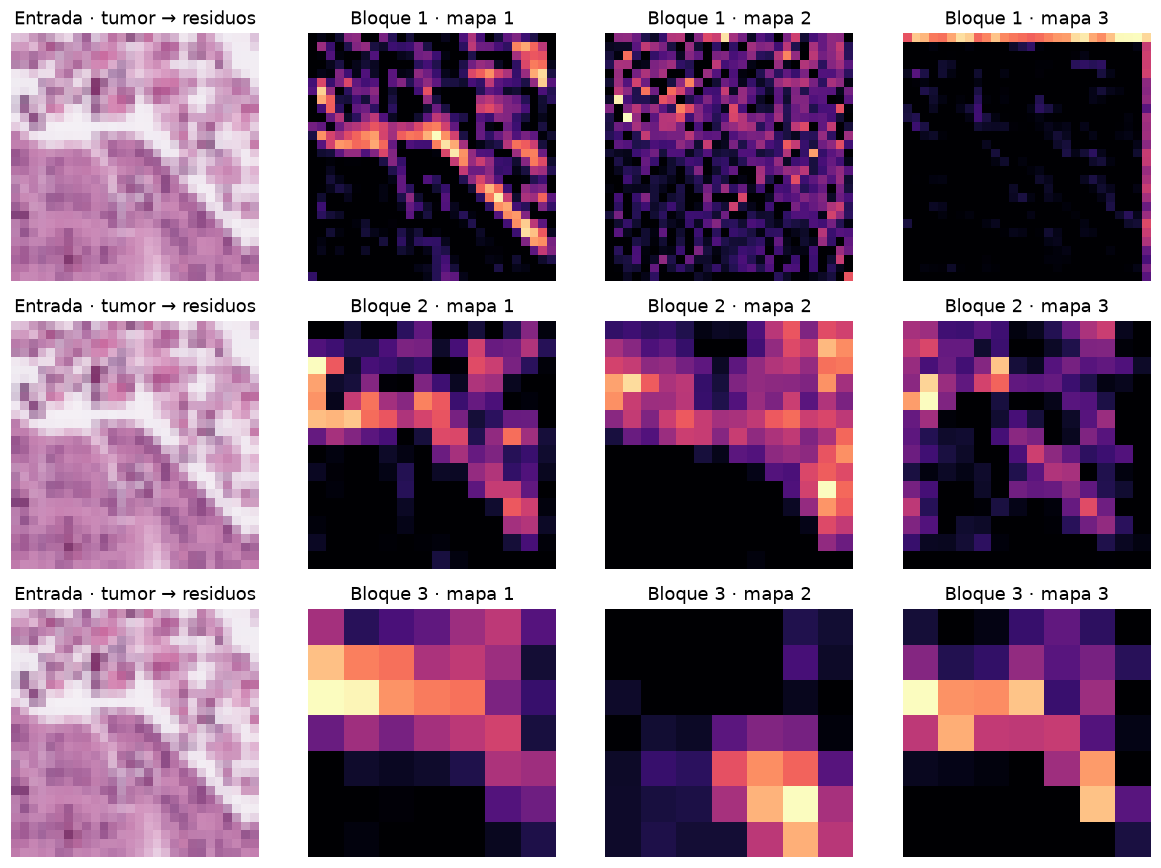

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for block in range(1, 4):
    axes[block-1, 0].imshow(plt.imread(EVIDENCE / 'examples' / 'feature_input.png'))  # Repite la misma entrada del baseline en cada fila para compararla con los distintos bloques
    axes[block-1, 0].set_title('Entrada · tumor → residuos')
    axes[block-1, 0].axis('off')
    for channel in range(3):
        ax = axes[block-1, channel+1]
        ax.imshow(plt.imread(EVIDENCE / 'examples' / f'bloque_{block}_{channel}.png'))  # Lee activaciones ya guardadas con escala propia por mapa, sin ejecutar inferencia
        ax.set_title(f'Bloque {block} · mapa {channel+1}')
        ax.axis('off')
plt.tight_layout()
plt.show()


## 9. Extensiones: AMP, aumentos, transferencia y GroupNorm

AMP/FP32 se compara con tres semillas emparejadas y una configuración fija de SimpleCNN. Las otras extensiones tienen una sola semilla. La comparación entre ResNet y SimpleCNN cambia arquitectura y preentrenamiento a la vez; no permite aislar el beneficio de ImageNet.

Los controles originales y las extensiones pueden diferir en la precisión de validación utilizada para seleccionar el checkpoint. Las métricas por clase mostradas son las guardadas, no nuevas evaluaciones.


,nombre,semilla,precision,val_macro_f1,minutos,peak_gpu_memory_mb
16,amp_comparison_seed42_amp,42,amp_fp16,0.966413,8.084385,217.646484
17,amp_comparison_seed42_fp32,42,fp32,0.970548,12.143414,351.717773
19,amp_comparison_seed43_amp,43,amp_fp16,0.904027,9.852889,217.646484
18,amp_comparison_seed43_fp32,43,fp32,0.921227,12.084839,351.717773
20,amp_comparison_seed44_amp,44,amp_fp16,0.946931,32.783632,217.646484
21,amp_comparison_seed44_fp32,44,fp32,0.921938,12.592239,351.717773


val_macro_f1            ... peak_gpu_memory_mb            
precision     amp_fp16      fp32  ...           amp_fp16        fp32
semilla                           ...                               
42            0.966413  0.970548  ...         217.646484  351.717773
43            0.904027  0.921227  ...         217.646484  351.717773
44            0.946931  0.921938  ...         217.646484  351.717773

[3 rows x 6 columns]

val_macro_f1              minutos            peak_gpu_memory_mb     
                  mean       std       mean        std               mean  std
precision                                                                     
amp_fp16      0.939124  0.031918  16.906969  13.777998         217.646484  0.0
fp32          0.937904  0.028272  12.273498   0.277588         351.717773  0.0

,nombre,modelo,normalizacion,aumentos,val_macro_f1,tumor_recall,minutos,peak_gpu_memory_mb
23,resnet18_geometric,resnet18,batch,geometric,0.984174,0.975559,11.264115,207.614258
22,resnet18_pretrained,resnet18,batch,none,0.975785,0.972765,7.570367,207.614258
14,simplecnn_128_bn1_gap1_b32_acc4_cp0,simplecnn,batch,none,0.966413,0.977654,8.079097,217.646484
24,simplecnn_geometric,simplecnn,batch,geometric,0.965369,0.930168,9.228254,217.646484
26,simplecnn_128_groupnorm,simplecnn,group,none,0.957001,0.949721,13.052905,343.645020
25,simplecnn_geometric_color,simplecnn,batch,geometric_color,0.918146,0.942039,9.040485,217.646484


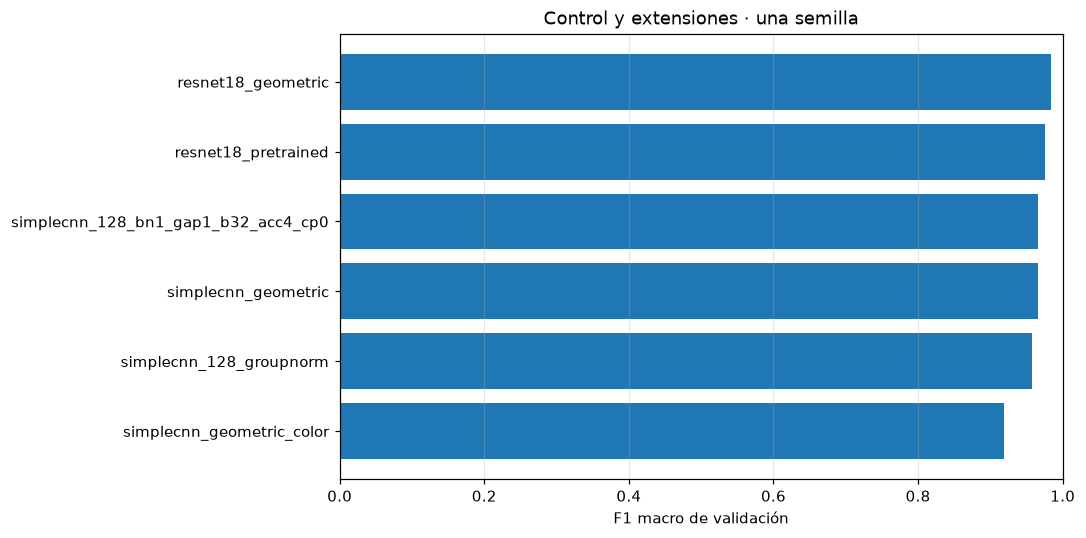

In [9]:
amp = summary.loc[summary['estudio'] == 'amp_comparison'].sort_values(['semilla', 'precision'])
display(amp[['nombre', 'semilla', 'precision', 'val_macro_f1', 'minutos', 'peak_gpu_memory_mb']])
paired = amp.pivot(index='semilla', columns='precision', values=['val_macro_f1', 'minutos', 'peak_gpu_memory_mb'])  # Alinea AMP y FP32 dentro de cada semilla para comparar experimentos emparejados
display(paired)
display(amp.groupby('precision')[['val_macro_f1', 'minutos', 'peak_gpu_memory_mb']].agg(['mean', 'std']))  # Resume media y desviación estándar entre tres semillas sin afirmar equivalencia estadística

extensions = summary.loc[(summary['modelo'] == 'resnet18')
                         | (summary['aumentos'] != 'none') | (summary['normalizacion'] == 'group')]
control = summary.loc[summary['nombre'] == 'simplecnn_128_bn1_gap1_b32_acc4_cp0']  # Usa el control con BatchNorm, GAP y lote 32×4 como referencia de las extensiones
extension_comparison = pd.concat([control, extensions]).sort_values('val_macro_f1', ascending=False)  # Reúne resultados exploratorios, sus diferencias no aíslan una única causa entre arquitecturas
display(extension_comparison[['nombre', 'modelo', 'normalizacion', 'aumentos',
                              'val_macro_f1', 'tumor_recall', 'minutos', 'peak_gpu_memory_mb']])
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(extension_comparison['nombre'], extension_comparison['val_macro_f1'])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='F1 macro de validación', title='Control y extensiones · una semilla')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Evaluación final completada

La selección quedó fijada antes de abrir test en `results/final_selection.json`: mayor F1 macro de validación entre las corridas completas, con empate por orden de ruta. Dentro de la corrida se utiliza el checkpoint de menor pérdida de validación.

Modelo final: ResNet-18 a 128×128, con giros y volteos durante entrenamiento. La evaluación de las 7.180 imágenes oficiales de test se hizo sin aumentos y en FP32. Esta sección lee sus archivos; no ejecuta test otra vez ni elige una corrida por su resultado en test.

Se obtuvo 91,53 % de exactitud, 0,8843 de F1 macro y 94,81 % de recall de tumor. El F1 macro pasó de 0,9842 en validación a 0,8843 en test: una caída de 0,0998, equivalente a 9,98 puntos porcentuales al expresar F1 en porcentaje. El resultado de validación no representa por sí solo el rendimiento observado en test.


F1 macro test - validación: -0.0998
Corrida original de MLflow: cda8d58f5cfc4ffa8e4887204aa07835


,particion,imagenes,accuracy,macro_f1,recall_tumor
0,Validación,10004,0.983906,0.984174,0.975559
1,Test,7180,0.915320,0.884345,0.948094


,precision,recall,f1-score,support
adipose,0.995208,0.931241,0.962162,1338.0
background,0.996471,1.000000,0.998232,847.0
debris,0.627863,0.970501,0.762457,339.0
lymphocytes,0.983903,0.771293,0.864721,634.0
mucus,0.983431,0.974879,0.979136,1035.0
smooth_muscle,0.730897,0.743243,0.737018,592.0
normal_colon,0.943717,0.973009,0.958140,741.0
stroma,0.725225,0.764846,0.744509,421.0
tumor_epithelium,0.957412,0.948094,0.952730,1233.0


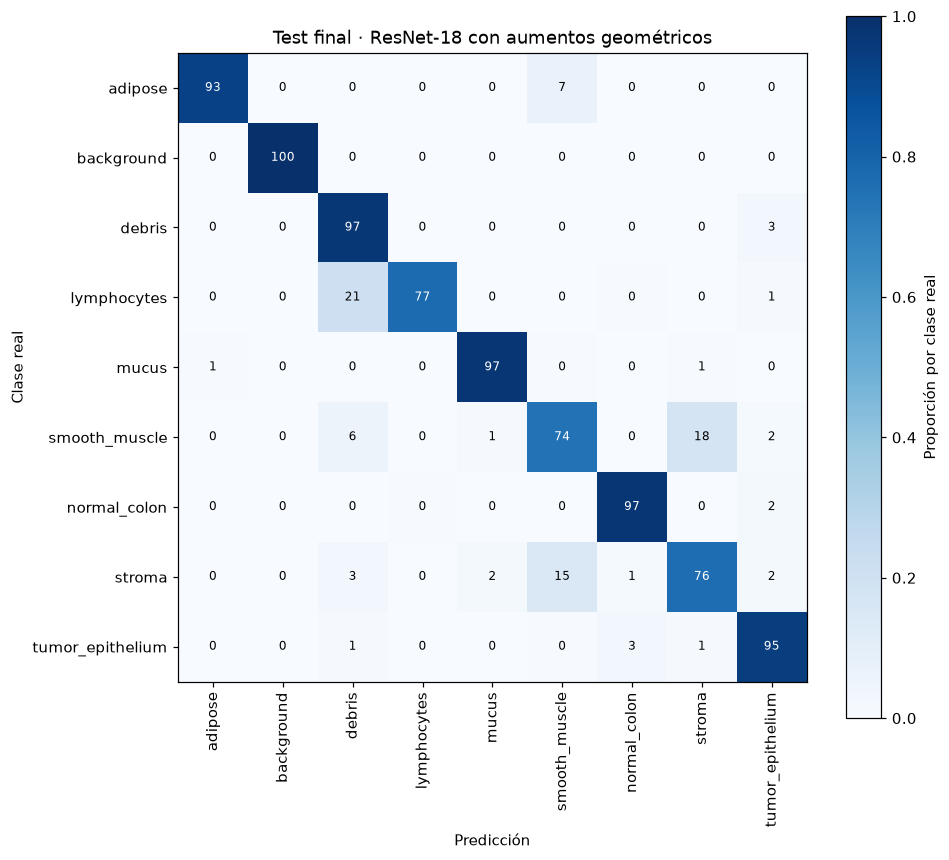

,clase_real,prediccion,casos
26,lymphocytes,debris,136
46,smooth_muscle,stroma,104
4,adipose,smooth_muscle,89
61,stroma,smooth_muscle,62
42,smooth_muscle,debris,33
70,tumor_epithelium,normal_colon,31
55,normal_colon,tumor_epithelium,15
66,tumor_epithelium,debris,13


In [10]:
final_run = run_paths[SELECTION['run']]  # Carga exclusivamente la corrida fijada antes de test y reutiliza sus resultados guardados
final_config = json.loads((final_run / 'config.json').read_text())
final_validation = json.loads((final_run / 'validation_metrics.json').read_text())
final_test = json.loads((final_run / 'test_metrics.json').read_text())
assert np.isclose(final_validation['macro avg']['f1-score'], SELECTION['validation_macro_f1'])  # Comprueba que la validación coincide con el registro de selección dentro de la tolerancia numérica
comparison_final = pd.DataFrame([
    {'particion': name, 'imagenes': int(report['macro avg']['support']),
     'accuracy': report['accuracy'], 'macro_f1': report['macro avg']['f1-score'],
     'recall_tumor': report['tumor_epithelium']['recall']}
    for name, report in [('Validación', final_validation), ('Test', final_test)]
])
display(comparison_final)
print('F1 macro test - validación:', round(final_test['macro avg']['f1-score'] - SELECTION['validation_macro_f1'], 4))  # El signo negativo indica menor F1 en test, sin usar esta diferencia para reajustar el modelo
display(pd.DataFrame(final_test).T.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']])  # Separa las nueve clases de los promedios globales para localizar tejidos con peor rendimiento
final_matrix = pd.read_csv(final_run / 'confusion_matrix.csv', index_col=0)
plot_confusion(final_matrix, 'Test final · ResNet-18 con aumentos geométricos')
display(error_pairs(final_matrix).head(8))  # Muestra errores de test como evidencia descriptiva del modelo ya elegido
print('Corrida original de MLflow:', final_config.get('mlflow_run_id'))


## 11. Interpretación y límites

- Hipótesis principal con BN y GAP: frente al baseline de 28×28, 64×64 reduce tumor → residuos de 24,30 % a 0 % y aumenta el recall de tumor de 0,5649 a 0,9811. A 128×128, la confusión es 10,96 % y el recall 0,7053: mejora frente a 28, pero no frente a 64. El detalle adicional no garantiza una mejora monótona
- Sin BN y con GAP: 64 y 128 también mejoran frente a 28; entre 64 y 128, tumor → residuos pasa de 0,35 % a 0,42 %. Deben distinguirse recall, confusión dirigida y rendimiento global
- Memoria y lote físico: acumulación y checkpointing permiten reducir memoria, pero BatchNorm ve el lote físico, no el efectivo. Comparar 128×1 con 32×4 no mantiene sus estadísticas de entrenamiento idénticas
- AMP/FP32: hay tres semillas emparejadas. AMP reduce el pico de memoria, pero el tiempo de la semilla 44 es atípico y su causa no quedó registrada. No se afirma aceleración general ni equivalencia estadística
- Extensiones: los aumentos geométricos mejoran ResNet en esta semilla, pero no SimpleCNN. Color empeora SimpleCNN y GroupNorm no supera al control con BatchNorm. Son observaciones de estas corridas, no superioridad general de un método
- Generalización final: el F1 macro de test es 0,8843 frente a 0,9842 en validación. Músculo liso, estroma y residuos tienen los F1 de test más bajos. Las matrices permiten localizar confusiones, pero no prueban por sí solas la causa de la caída
- Cierre: la resolución, el clasificador y la normalización cambian errores concretos y costo computacional. La mejor validación no elimina la necesidad de evaluación independiente. No se vuelve a ajustar el modelo con test; las nuevas hipótesis requieren experimentos futuros con un protocolo de evaluación separado

La evidencia permanece en `results/`; los modelos y datos originales, en `runs/` y `data/`; el historial completo de seguimiento, en `mlflow.db` y `mlartifacts/`.
